In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# EL PROBLEMA

Se quiere predecir la supervivencia en meses de las pacientes con cáncer de mama con carcinoma ductal infiltrante y carcinoma lobulillar infiltrante, en base a su diagnóstico basado en diferentes aspectos como tamaño, número de ganglios, metátasis, diferenciación, etc.

## CONCEPTOS SOBRE DIAGNÓSTICO DEL CÁNCER DE MAMA

En este dataset se utilizan las siguientes clasificaciones para describir el estado de la enfermedad de cáncer de mama:

1) El TNM, que es el sistema estándar internacional para describir la exténsión anatómica del cáncer. En cáncer de mama, las letras significan:

- T (Tumor): tamaño y extensión del tumor primario --> Columna: 'T Stage' y 'Tumor Size'
- N (Nodes): afectación de ganglios linfáticos regionales --> Columna: 'N Stage'
- M (Metastasis): presencia o ausencia de metástasis a distancia. 

2) 6th Stage, que es el estadio clínico del cáncer de mama según la clasificación AJCC (6.ª edición), que refleja el grado de extensión de la enfermedad.

3) Grado de diferenciación tumoral, que explica cuanto se parecen las células cancerígenas a las células mamarias normales --> Columnas: 'Grade' y 'differentiate'.

4) A Stage, que es el estadio anatómico global derivado de la clasificación TNM, que resume la extensión del cáncer de mama en los estadios I, II, III o IV.

5) Estrogen Status y Progesterone Status, indican si el cácer de mama está relacionado hormonalmente o no. Se utiliza para poner el tratamiento al paciente.

6) Regional Node Examined and Regional Node Positive, indican cuántos gánglios linfáticos regionales fueron examinados y cuántos de ellos dieron positivo.


Por las definiciones, tenemos variables que estarán muy relacionadas entre sí.

Relación TNM y A Stage:

| T Stage   | Tumor Size    | N Stage   | M | A Stage   |
| ---   | ---   | ---   | ---   | ---   |
| T1    | <= 2 cm   | N0    | M0    | I |
| T1    | <= 2 cm   | N1    | M0    | II    |
| T2    | > 2 <= 5 cm   | N0    | M0    | II    |
| T2    | > 2 <= 5 cm   | N1    | M0    | II    |
| T3    | > 5 cm    | N0 - N1   | M0    | III   |
| T1 - T3   | Cualquier | N2 - N3   | M0    | III   |
| T4    | Invasión de piel o pared torácica | Cualquier | M0    | III   |
| Cualquiera    | Cualquier | Cualquier | M1    | IV    |

Relación Grade y Differenciate:

| Grade | Differenciate |
| ---   | --- |
| 1 | Well differentiated   |
| 2 | Moderately differentiated |
| 3 | Poorly differentiated |
| 4 | Undifferentiated  |



### ***El mejor pronóstico de la enfermedad es el que menor estadio (A Stage) y grado (Grade) tienen.***




# EDA

## HIPÓTESIS

1) ¿Cómo se distribuye la supervivencia?
2) ¿Qué variables parecen influir más?
3) ¿Existen outliers?
4) ¿Hay variables redundantes?
5) Feature Engineering

In [5]:
archivo = '../data/raw/Breast_Cancer.csv'
df = pd.read_csv(archivo)
df.head()

,Age,Race,Marital Status,T Stage,N Stage,6th Stage,differentiate,Grade,A Stage,Tumor Size,Estrogen Status,Progesterone Status,Regional Node Examined,Reginol Node Positive,Survival Months,Status
0,68,White,Married,T1,N1,IIA,Poorly differentiated,3,Regional,4,Positive,Positive,24,1,60,Alive
1,50,White,Married,T2,N2,IIIA,Moderately differentiated,2,Regional,35,Positive,Positive,14,5,62,Alive
2,58,White,Divorced,T3,N3,IIIC,Moderately differentiated,2,Regional,63,Positive,Positive,14,7,75,Alive
3,58,White,Married,T1,N1,IIA,Poorly differentiated,3,Regional,18,Positive,Positive,2,1,84,Alive
4,47,White,Married,T2,N1,IIB,Poorly differentiated,3,Regional,41,Positive,Positive,3,1,50,Alive


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 4024 entries, 0 to 4023
Data columns (total 16 columns):
 #   Column                  Non-Null Count  Dtype
---  ------                  --------------  -----
 0   Age                     4024 non-null   int64
 1   Race                    4024 non-null   str  
 2   Marital Status          4024 non-null   str  
 3   T Stage                 4024 non-null   str  
 4   N Stage                 4024 non-null   str  
 5   6th Stage               4024 non-null   str  
 6   differentiate           4024 non-null   str  
 7   Grade                   4024 non-null   str  
 8   A Stage                 4024 non-null   str  
 9   Tumor Size              4024 non-null   int64
 10  Estrogen Status         4024 non-null   str  
 11  Progesterone Status     4024 non-null   str  
 12  Regional Node Examined  4024 non-null   int64
 13  Reginol Node Positive   4024 non-null   int64
 14  Survival Months         4024 non-null   int64
 15  Status                  4024 non

In [13]:
df.isnull().sum() # verificamos que no hay valores nulos

Age                       0
Race                      0
Marital Status            0
T Stage                   0
N Stage                   0
6th Stage                 0
differentiate             0
Grade                     0
A Stage                   0
Tumor Size                0
Estrogen Status           0
Progesterone Status       0
Regional Node Examined    0
Reginol Node Positive     0
Survival Months           0
Status                    0
dtype: int64

In [15]:
df.duplicated().sum() # verificamos que no hay valores duplicados

np.int64(1)

Aparece un valor duplicado. Análisis: son datos anonimizados, y dos pacientes pueden tener los mismos datos según esta clasificación por lo que no se puede eliminar

### Target

Nuestra variable objetivo es Survival Months.

y = df['Survival Months']

In [6]:
# Análisis variable objetivo

df['Survival Months'].describe()

count    4024.000000
mean       71.297962
std        22.921430
min         1.000000
25%        56.000000
50%        73.000000
75%        90.000000
max       107.000000
Name: Survival Months, dtype: float64

In [23]:
print("Media", df['Survival Months'].mean())
print("Mediana", df['Survival Months'].median())
print("Moda", df['Survival Months'].mode())
print("Asimetría", df['Survival Months'].skew()) # Simétrica: -0.5 < skew < 0.5; Simetría positiva: skew > 0.5; Simetría negativa: skew < -0.5
print("Curtosis", df['Survival Months'].kurtosis()) # Explica si la variable tiene colas muy pesadas o valores extremos

Media 71.29796222664015
Mediana 73.0
Moda 0    69
Name: Survival Months, dtype: int64
Asimetría -0.589998326716996
Curtosis 0.019977498335181476


Al ser la media y la mediana muy parecidas (71.3 y 73.0) indica que tiene una distribución equilibrada.

La desviación estándar es grande, aproximadamente 23 meses, por lo que el rango de supervivencia queda entre 48 y 94 meses.

La moda nos indica que el valor más frecuente en esta columna es 69 meses.

Hay una diferencia muy grande entre el mínimo, 1 mes, y el máximo, 107 meses.

La asimetría de -0.59 nos indica que tenemos una asimetría negativa moderada, es decir, que tenemos unos pocos pacientes que sobrevivieron muy pocos meses pero la mayoría tienen una supervivencia media-alta.

El valor de curtosis es prácticamente 0, por lo que tiene una distribución normal sin muchos datos con valores extremos.

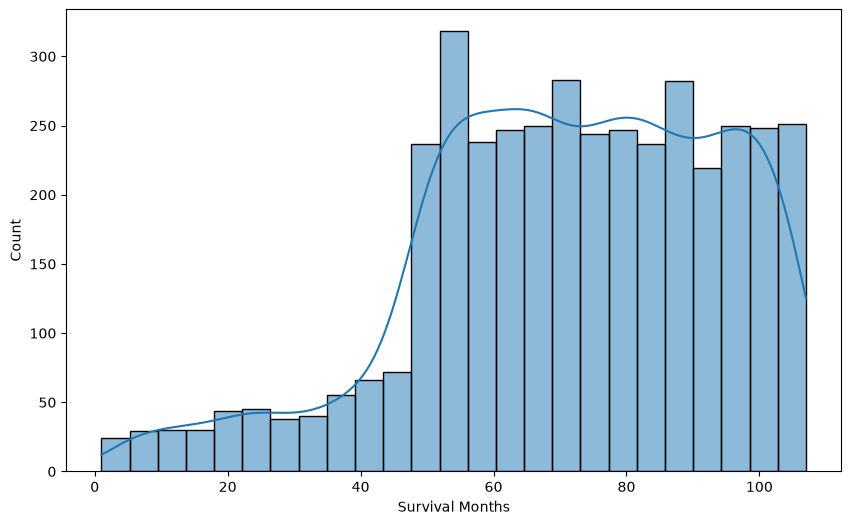

In [7]:
plt.figure(figsize=(10,6)) # Con este gráfico no solo se muestra la supervivencia en meses, la línea de kde muestra el histograma como si fuese una línea contínua

sns.histplot(df['Survival Months'],kde=True)
plt.show()

Ahora vamos a emplear el método IQR (rango intercuartílico) para verificar si hay outliers.

Un outlier sería si la supervivencia de un paciente es extremadamente baja o extremadamente alta.

In [ ]:
'''
A partir de los datos generados anteriormente en el análisis descriptivo, tenemos:
25% = 56 meses
50% = 73 meses
75% = 90 meses
'''
Q1 = 56
Q2 = 73
Q3 = 90

# IQR = Q3 - Q1

IQR = 90 - 56

IQR = 34

# La parte central donde se concentran el 50% de los pacientes tiene una amplitud de 34 meses.

In [11]:
'''
Cálculo de los límites de los outliers
 Límite inferior: Q1 - 1.5*IQR
 Límite superior: Q3 + 1.5*IQR
'''
# Límite inferior
lim_inf = 56 - 1.5*34
lim_inf = 5

# Límite superior
lim_sup = 90 + 1.5*34
lim_sup = 141

Se realizó la detección de valores atípicos mediante el método del rango intercuartílico (IQR). El primer cuartil fue de 56 meses y el tercer cuartil de 90 meses, obteniéndose un IQR de 34 meses. Los límites calculados fueron 5 y 141 meses. Se identificaron posibles valores atípicos únicamente en la cola inferior de la distribución (supervivencias menores a 5 meses).

Pero, ¿qué hacemos con los outliers?

Este es un dataset de cáncer de mama, en el que los pacientes con un estado de la enfermedad avanzado, sobreviven muy pocos meses, por lo que tienen relevancia clínica y no se pueden eliminar.

Ahora pasamos a analizar las siguientes variables relacionadas con la supervivencia:
- T Stage
- N Stage
- 6th Stage
- Grade
- Age
- Tumor Size
- Reginol Node Positive

In [5]:
df.head()

,Age,Race,Marital Status,T Stage,N Stage,6th Stage,differentiate,Grade,A Stage,Tumor Size,Estrogen Status,Progesterone Status,Regional Node Examined,Reginol Node Positive,Survival Months,Status
0,68,White,Married,T1,N1,IIA,Poorly differentiated,3,Regional,4,Positive,Positive,24,1,60,Alive
1,50,White,Married,T2,N2,IIIA,Moderately differentiated,2,Regional,35,Positive,Positive,14,5,62,Alive
2,58,White,Divorced,T3,N3,IIIC,Moderately differentiated,2,Regional,63,Positive,Positive,14,7,75,Alive
3,58,White,Married,T1,N1,IIA,Poorly differentiated,3,Regional,18,Positive,Positive,2,1,84,Alive
4,47,White,Married,T2,N1,IIB,Poorly differentiated,3,Regional,41,Positive,Positive,3,1,50,Alive


In [6]:
# Análisis univariante de Age

df['Age'].describe()

count    4024.000000
mean       53.972167
std         8.963134
min        30.000000
25%        47.000000
50%        54.000000
75%        61.000000
max        69.000000
Name: Age, dtype: float64

In [9]:
print("Media", df['Age'].mean())
print("Mediana", df['Age'].median())
print("Moda", df['Age'].mode())
print("Asimetría", df['Age'].skew()) 
print("Curtosis", df['Age'].kurtosis())

Media 53.97216699801193
Mediana 54.0
Moda 0    46
Name: Age, dtype: int64
Asimetría -0.2203727859678868
Curtosis -0.7550875306304676


La media y la mediana para la edad se podrían decir que son iguales (53.97 frente 54.0), por lo que indica una distribución equilibrada y sin sesgos.

El valor más repetido es 46 años.

El valor de asimetría es -0.22 lo que indica que la distribución es prácticamente simétrica.

El valor de curtosis -0.75 nos indica que es una distribución más plana de lo normal en el centro, y con menos valores extremos de los esperados.